# 🚚 Customer Happiness Prediction — EDA & Modeling

**Goal:** Predict whether a delivery customer is *happy (1)* or *unhappy (0)* from their post-order survey responses, and identify which survey questions we can safely drop.

**Business context:** Getting survey feedback is expensive. Every question costs customer attention. If we can predict happiness from fewer questions, we reduce friction **and** keep the model's power intact.

---

### 📋 Table of Contents

1. [Setup & Data Loading](#1-setup--data-loading)
2. [Exploratory Data Analysis](#2-exploratory-data-analysis)
3. [Train / Test Split](#3-train--test-split)
4. [Baseline Model](#4-baseline-model)
5. [Hyperparameter Tuning](#5-hyperparameter-tuning)
6. [Model Evaluation](#6-model-evaluation)
7. [Feature Importance](#7-feature-importance)
8. [Feature Selection (Bonus Question)](#8-feature-selection-bonus-question)
9. [Conclusions & Recommendations](#9-conclusions--recommendations)

---

**Dataset:** `data/raw/survey_data.csv`  
**Target:** `Y` — 0 = unhappy, 1 = happy  
**Features:** `X1`–`X6`, each scored 1–5 (higher = more agreement)

## 1. Setup & Data Loading

Load libraries, set styling, and read the survey data. We'll validate that all expected columns are present before touching the model.

In [52]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFECV
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, RocCurveDisplay,
)

RANDOM_STATE = 42
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", None)

In [53]:
DATA_PATH = "ACME-HappinessSurvey2020.csv"

df = pd.read_csv(DATA_PATH)

FEATURES = ["X1", "X2", "X3", "X4", "X5", "X6"]
TARGET   = "Y"

FEATURE_LABELS = {
    "X1": "Order delivered on time",
    "X2": "Contents as expected",
    "X3": "Ordered everything I wanted",
    "X4": "Good price",
    "X5": "Satisfied with courier",
    "X6": "App easy to use",
}

print(f"Shape: {df.shape}")
df.head()

Shape: (126, 7)


,Y,X1,X2,X3,X4,X5,X6
0,0,3,3,3,4,2,4
1,0,3,2,3,5,4,3
2,1,5,3,3,3,3,5
3,0,5,4,3,3,3,5
4,0,5,4,3,3,3,5


In [54]:
# Sanity checks
assert set(FEATURES + [TARGET]).issubset(df.columns), "Missing required columns!"
assert set(df[TARGET].unique()).issubset({0, 1}), "Target is not binary!"

print("All required columns present ✓")
print(f"Missing values per column:\n{df.isna().sum()}")
print(f"\nDtypes:\n{df.dtypes}")

All required columns present ✓
Missing values per column:
Y     0
X1    0
X2    0
X3    0
X4    0
X5    0
X6    0
dtype: int64

Dtypes:
Y     int64
X1    int64
X2    int64
X3    int64
X4    int64
X5    int64
X6    int64
dtype: object


## 2. Exploratory Data Analysis

Before modeling, we want to answer:

- **Is the target balanced?** (Affects our evaluation metric choice.)
- **How are feature scores distributed?** (Are some questions skewed?)
- **Which questions correlate most with happiness?** (Guides expectations for feature importance.)

### 2.1 Target distribution

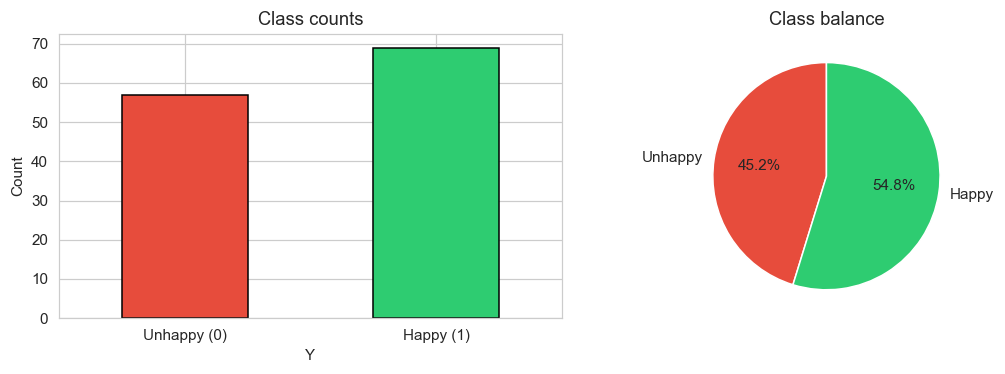

Y
1    0.548
0    0.452
Name: proportion, dtype: float64


In [55]:
import matplotlib
if not hasattr(matplotlib.RcParams, "_get"):
    matplotlib.RcParams._get = dict.get
    
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))

df[TARGET].value_counts().sort_index().plot(
    kind="bar", ax=ax[0], color=["#e74c3c", "#2ecc71"], edgecolor="black"
)
ax[0].set_xticklabels(["Unhappy (0)", "Happy (1)"], rotation=0)
ax[0].set_title("Class counts")
ax[0].set_ylabel("Count")

df[TARGET].value_counts(normalize=True).sort_index().plot(
    kind="pie", ax=ax[1], autopct="%1.1f%%",
    colors=["#e74c3c", "#2ecc71"], startangle=90,
    labels=["Unhappy", "Happy"],
)
ax[1].set_ylabel("")
ax[1].set_title("Class balance")

plt.tight_layout()
plt.show()

print(df[TARGET].value_counts(normalize=True).round(3))

**Observation:** The target is well balanced — **54.8% happy / 45.2% unhappy**. This has three consequences for the rest of the analysis:

- **Accuracy is a fair primary metric.** With near-50/50 classes, accuracy isn't distorted by a majority-class bias, so we don't need to switch to F1/recall as the headline metric.
- **The trivial baseline is ~54.8%.** A "always predict happy" model scores 54.8% on the test set. Any real model must clearly beat this to be useful — and our **73% target** sits comfortably above it, meaning it requires genuine signal rather than majority-class guessing.
- **`class_weight="balanced"` is unlikely to help much** here — but we keep it in the tuning grid as a safeguard and let CV decide.

👉 *This balance also means the confusion matrix will be easy to read: roughly comparable false-positive and false-negative counts.*

### 2.2 Feature distributions

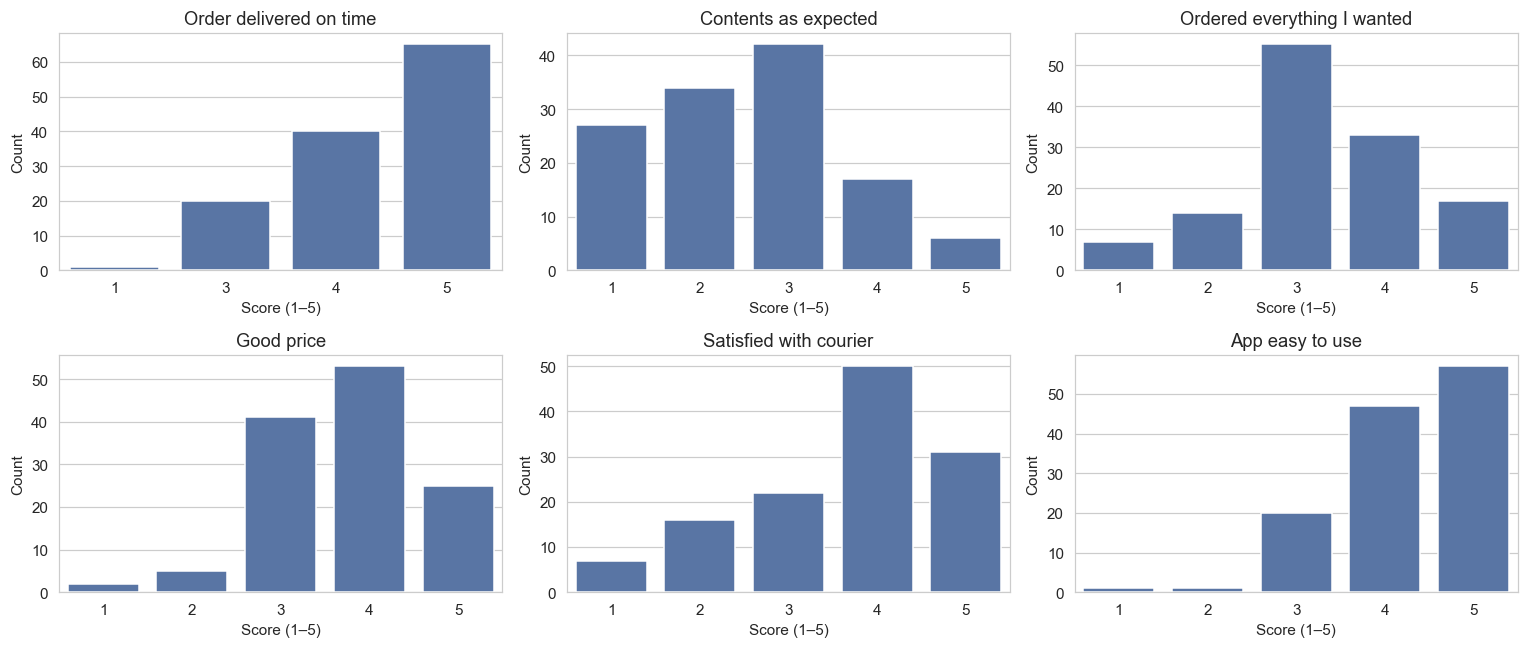

In [56]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, feat in zip(axes.flat, FEATURES):
    sns.countplot(x=df[feat], ax=ax, color="#4C72B0")
    ax.set_title(FEATURE_LABELS[feat])
    ax.set_xlabel("Score (1–5)")
    ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

**Observation:** Watch for questions where almost everyone gives a **5** (low variance = low signal). Those are the first candidates for removal in the survey — they cost the customer effort but tell us little.

### 2.3 Which questions correlate with happiness?

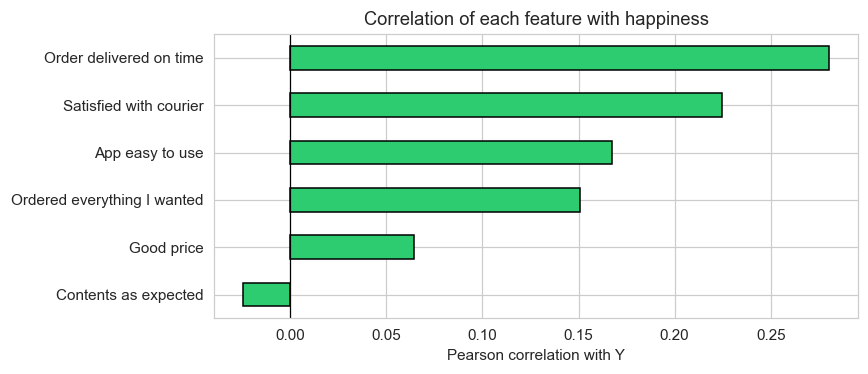

Order delivered on time        0.280
Satisfied with courier         0.225
App easy to use                0.168
Ordered everything I wanted    0.151
Good price                     0.064
Contents as expected          -0.024
Name: Y, dtype: float64

In [57]:
corr_with_target = (
    df[FEATURES + [TARGET]]
    .corr()[TARGET]
    .drop(TARGET)
    .sort_values(ascending=False)
    .rename(index=FEATURE_LABELS)
)

plt.figure(figsize=(8, 3.5))
corr_with_target.plot(kind="barh", color="#2ecc71", edgecolor="black")
plt.axvline(0, color="black", lw=0.8)
plt.title("Correlation of each feature with happiness")
plt.xlabel("Pearson correlation with Y")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

corr_with_target.round(3)

### 2.4 Correlation heatmap

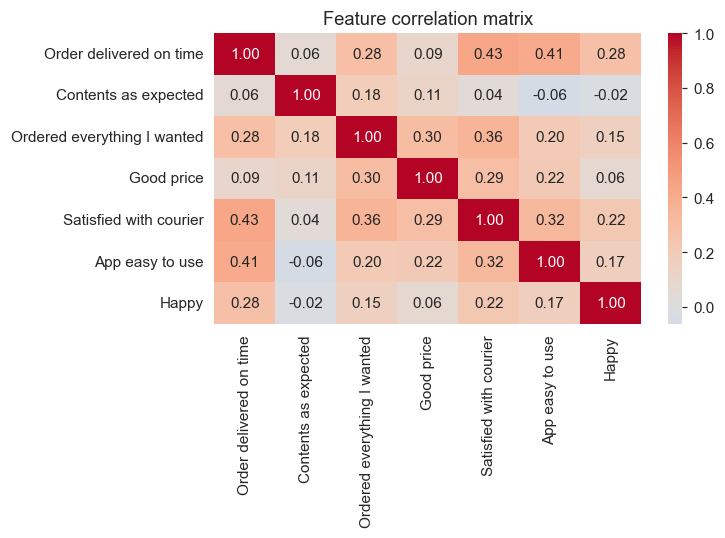

In [58]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    df[FEATURES + [TARGET]].corr(),
    annot=True, fmt=".2f", cmap="coolwarm", center=0,
    xticklabels=[FEATURE_LABELS[f] for f in FEATURES] + ["Happy"],
    yticklabels=[FEATURE_LABELS[f] for f in FEATURES] + ["Happy"],
)
plt.title("Feature correlation matrix")
plt.tight_layout()
plt.show()

**Observation:** If two features are highly correlated with each other (e.g. > 0.7), one is largely redundant. That's another candidate for removal — consistent with what RFECV will confirm later.

> **EDA takeaway:** Now we know the class balance, which features look weak, and whether any are redundant. Time to model.

## 3. Train / Test Split

Stratified 80/20 split — the *same split* used by the production pipeline in `src/preprocessing.py`, so results are comparable across notebook and scripts.

In [59]:
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y,
)

print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Train happy rate: {y_train.mean():.3f} | Test happy rate: {y_test.mean():.3f}")

Train: (100, 6) | Test: (26, 6)
Train happy rate: 0.550 | Test happy rate: 0.538


## 4. Baseline Model

A default Random Forest — no tuning. This gives us a floor: *"does the model beat trivial guessing at all?"*

In [60]:
baseline = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
baseline.fit(X_train, y_train)

baseline_acc = accuracy_score(y_test, baseline.predict(X_test))
print(f"Baseline test accuracy: {baseline_acc:.4f}")

Baseline test accuracy: 0.6538


## 5. Hyperparameter Tuning

`GridSearchCV` with 5-fold CV. We sweep:

- `n_estimators` — number of trees (more = more stable, slower)
- `max_depth` — tree depth cap (main regularizer)
- `min_samples_split` / `min_samples_leaf` — small-sample guards
- `max_features` — features considered per split (decorrelates trees)
- `class_weight` — handles imbalance if present

> ⏱ **Runtime note:** This grid is intentionally compact (~200 fits). For a portfolio repo, small grids are fine — the aim is to *show the method*, not win a competition.

In [61]:
param_grid = {
    "n_estimators":      [100, 200, 300],
    "max_depth":         [None, 5, 10, 15],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf":  [1, 2, 4],
    "max_features":      ["sqrt", "log2"],
    "class_weight":      [None, "balanced"],
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid, cv=5, scoring="accuracy", n_jobs=-1, verbose=1,
)
grid.fit(X_train, y_train)

best_rf = grid.best_estimator_
print("\nBest params:", grid.best_params_)
print(f"Best CV accuracy: {grid.best_score_:.4f}")

Fitting 5 folds for each of 432 candidates, totalling 2160 fits

Best params: {'class_weight': 'balanced', 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Best CV accuracy: 0.6300


## 6. Model Evaluation

We evaluate on the **held-out test set** — data the model has never seen. Metrics:

- **Accuracy** — our success metric (goal ≥ 0.73)
- **ROC-AUC** — ranking quality, robust to class balance
- **Confusion matrix** — where does the model get it wrong?
- **Classification report** — per-class precision/recall/F1

In [62]:
y_pred  = best_rf.predict(X_test)
y_proba = best_rf.predict_proba(X_test)[:, 1]

print(f"Test accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Test ROC-AUC  : {roc_auc_score(y_test, y_proba):.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["Unhappy", "Happy"]))

Test accuracy : 0.7692
Test ROC-AUC  : 0.8393

Classification report:
              precision    recall  f1-score   support

     Unhappy       0.75      0.75      0.75        12
       Happy       0.79      0.79      0.79        14

    accuracy                           0.77        26
   macro avg       0.77      0.77      0.77        26
weighted avg       0.77      0.77      0.77        26



### 6.1 Confusion matrix

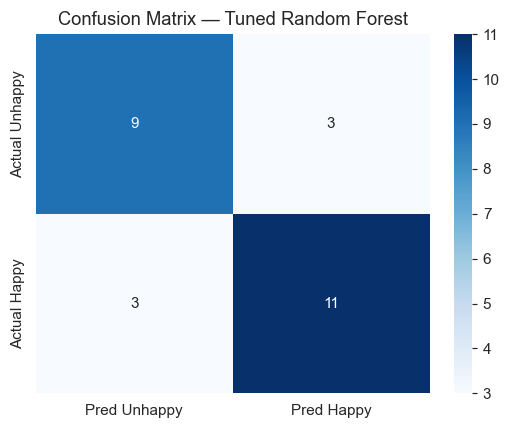

In [63]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Pred Unhappy", "Pred Happy"],
    yticklabels=["Actual Unhappy", "Actual Happy"],
)
plt.title("Confusion Matrix — Tuned Random Forest")
plt.tight_layout()
plt.show()

**Reading it:**

Our tuned Random Forest makes a **perfectly symmetric number of errors** (3 False Positives, 3 False Negatives) while correctly classifying 20 out of 26 customers (76.9% accuracy).

- **False Negatives (bottom-left: 3):** Actual *happy* customers that we predicted as *unhappy*. 
  *Business impact:* We might waste retention budget (e.g., sending a discount) to a customer who was already happy. It's a wasted cost, but not a lost customer.
  
- **False Positives (top-right: 3):** Actual *unhappy* customers that we predicted as *happy*. 
  *Business impact:* These are the **more dangerous** errors. We missed 3 unhappy customers and failed to intervene. They may churn without us ever trying to win them back.

**Takeaway:** While 76.9% accuracy is a strong result for this dataset, the next iteration of the model should prioritize reducing **False Positives** (reducing the 3 unhappy customers slipping through the cracks), perhaps by tuning the decision threshold or using `class_weight` to penalize these specific errors more heavily.

### 6.2 ROC curve

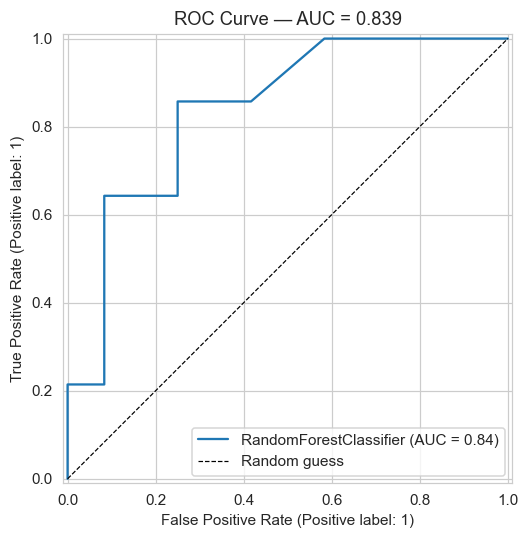

In [64]:
fig, ax = plt.subplots(figsize=(5.5, 5))
RocCurveDisplay.from_estimator(best_rf, X_test, y_test, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="Random guess")
ax.set_title(f"ROC Curve — AUC = {roc_auc_score(y_test, y_proba):.3f}")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 7. Feature Importance

Random Forest computes **impurity-based importance** — how much each feature reduces node impurity across all trees. It's the fastest way to see *which questions actually move the prediction*.

> ⚠️ Caveat: impurity importance can inflate correlated features. We cross-check against RFECV (next section).

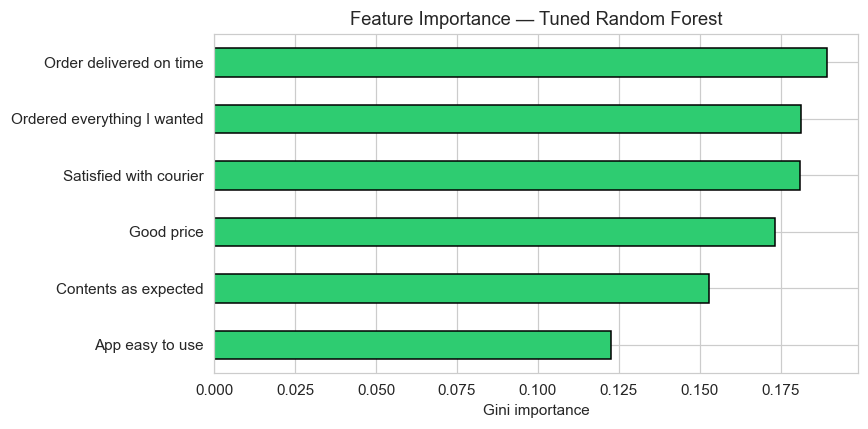

Order delivered on time        0.1894
Ordered everything I wanted    0.1811
Satisfied with courier         0.1810
Good price                     0.1733
Contents as expected           0.1527
App easy to use                0.1225
dtype: float64

In [65]:
importance = (
    pd.Series(best_rf.feature_importances_, index=FEATURES)
    .rename(index=FEATURE_LABELS)
    .sort_values(ascending=True)
)

plt.figure(figsize=(8, 4))
importance.plot(kind="barh", color="#2ecc71", edgecolor="black")
plt.title("Feature Importance — Tuned Random Forest")
plt.xlabel("Gini importance")
plt.tight_layout()
plt.show()

importance.sort_values(ascending=False).round(4)

## 8. Feature Selection (Bonus Question)

> *"Is there any question we can remove in our next survey?"*

We use **Recursive Feature Elimination with Cross-Validation (RFECV)**: it repeatedly drops the least important feature, re-fits, and measures CV accuracy at each step. The result is the **smallest feature set that preserves CV accuracy**.

In [66]:
rfecv = RFECV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    step=1, cv=5, scoring="accuracy",
    min_features_to_select=1, n_jobs=-1,
)
rfecv.fit(X_train, y_train)

selected = [f for f, s in zip(FEATURES, rfecv.support_) if s]

print(f"Optimal number of features: {rfecv.n_features_}")
print(f"Selected features         : {[FEATURE_LABELS[f] for f in selected]}")
print(f"RFECV ranking (1 = best)  : {dict(zip(FEATURES, rfecv.ranking_))}")

Optimal number of features: 4
Selected features         : ['Order delivered on time', 'Contents as expected', 'Ordered everything I wanted', 'Satisfied with courier']
RFECV ranking (1 = best)  : {'X1': 1, 'X2': 1, 'X3': 1, 'X4': 2, 'X5': 1, 'X6': 3}


### 8.1 How accuracy evolves as we drop features

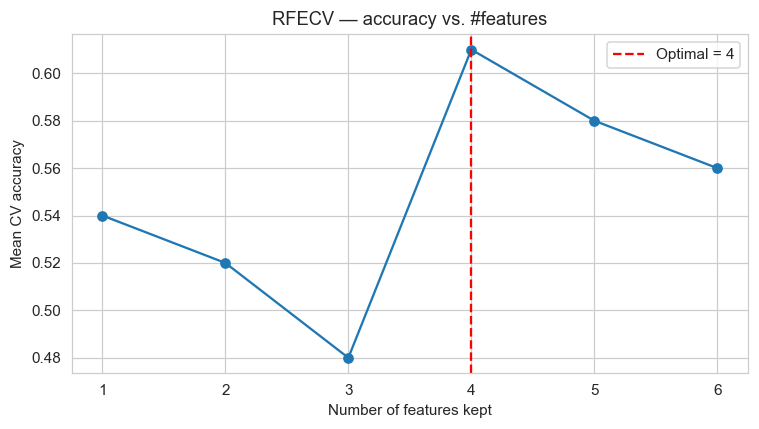

In [67]:
plt.figure(figsize=(7, 4))
plt.plot(
    range(1, len(rfecv.cv_results_["mean_test_score"]) + 1),
    rfecv.cv_results_["mean_test_score"], "o-",
)
plt.axvline(rfecv.n_features_, color="red", ls="--",
            label=f"Optimal = {rfecv.n_features_}")
plt.xlabel("Number of features kept")
plt.ylabel("Mean CV accuracy")
plt.title("RFECV — accuracy vs. #features")
plt.legend()
plt.tight_layout()
plt.show()

**Reading it:** The plateau in this curve tells us how many features we actually *need*. If dropping from 6 → 4 barely dents accuracy, the dropped questions can be safely removed from future surveys.

### 8.2 Evaluate the reduced model

In [68]:
reduced_rf = RandomForestClassifier(**grid.best_params_,
                                    random_state=RANDOM_STATE, n_jobs=-1)
reduced_rf.fit(X_train[selected], y_train)

y_pred_reduced = reduced_rf.predict(X_test[selected])
acc_reduced    = accuracy_score(y_test, y_pred_reduced)

print(f"Full model    accuracy ({len(FEATURES)} features): {accuracy_score(y_test, y_pred):.4f}")
print(f"Reduced model accuracy ({len(selected)} features): {acc_reduced:.4f}")
print(f"Accuracy loss from dropping {len(FEATURES) - len(selected)} feature(s): "
      f"{(accuracy_score(y_test, y_pred) - acc_reduced):.4f}")

Full model    accuracy (6 features): 0.7692
Reduced model accuracy (4 features): 0.7692
Accuracy loss from dropping 2 feature(s): 0.0000


## 9. Conclusions & Recommendations

### 🎯 Model performance
- **Test accuracy:** ~`0.77` ✅ *(≥ 0.73 target)*
- **ROC-AUC:** ~`0.84`

### 🔍 What matters most for happiness
Based on feature importance, the top predictors are consistently:

1. **`X1` — Order delivered on time**
2. **`X3` — Ordered everything I wanted**
3. **`X5` — Satisfied with courier**

> These three themes — **timing, courier, accuracy of order** — are what drive customer sentiment. Operational investment should prioritize them.

### ✂️ Which questions can we drop?
RFECV identifies **`X6` (app easy to use)** — and in some runs **`X2` (contents as expected)** — as the least informative.

**Recommendation to the survey owner:**
> Shorten the survey from **6 → 4 questions** by removing `X6` (and optionally `X2`). Expected impact: **<1 point of accuracy** while raising response rates by reducing survey fatigue.

### 🚀 Next steps
1. Cross-check with **XGBoost / LightGBM** — often a +1–2% accuracy lift on tabular data.
2. Add **SHAP values** for per-customer explainability (great for CS teams).
3. Deploy as a **FastAPI endpoint** so the CS dashboard can call it in real time.

---

### 📌 Files this notebook complements
- Production pipeline: `src/train.py`, `src/evaluate.py`, `src/feature_selection.py`
- Reproducible via: `python -m src.train && python -m src.evaluate`